# Compact transformer for discourse acts

Task #4: fine-tune DistilBERT on standardized Coarse Discourse and compare it with the existing baselines. Training and evaluation live in `artifacts/` and `scripts/`; this notebook runs those commands and inspects their outputs.

In VS Code, choose **Select Kernel → Colab → Auto Connect**, sign in, and select a GPU runtime. The notebook stays on your computer, but Python and file access run on the remote server. See the [extension guide](https://github.com/googlecolab/colab-vscode) and [supported features/workarounds](https://github.com/googlecolab/colab-vscode/wiki/Known-Issues-and-Workarounds).

Before running remotely, copy this checkout's `artifacts/` and `scripts/` folders to a project folder in Google Drive, including the new, currently uncommitted discourse modules and scripts. Copy the **full standardized** `reddit-coarse-discourse-corpus.jsonl` into that project's `data/local/standardized-v1/` folder. A fresh GitHub clone will only contain these files after they are committed and pushed; the full corpus is never tracked. Update the paths below to match your Drive folder.

Run cells in order. Defaults run one training epoch and dev evaluation. Full experiments and final test evaluation are disabled until you enable them. Checkpoints and outputs are written to Drive so completed runs survive a runtime reset. The current training script saves the best model but does not resume optimizer state after interruption; use a new run ID to restart.

## Install dependencies in the selected kernel
Keep Colab's preinstalled PyTorch/CUDA build when present. Restart the kernel if pip requests it, then continue below. These version ranges match the APIs used by the scripts; exact installed versions are recorded with each completed training run.

In [3]:
%pip install "torch>=2.3,<3" "transformers>=5,<6" "scikit-learn>=1.5,<2" "pydantic>=2,<3" numpy scipy pandas matplotlib

## Mount Drive and set paths
The extension supports `drive.mount()` in recent releases. If authentication fails, update the extension or use its **Colab: Mount Google Drive to Server...** command. Local kernels skip mounting. Local paths such as `/Users/...` cannot be read by a remote Colab kernel.

In [4]:
from pathlib import Path
import sys

IN_COLAB = Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

local_candidates = [Path.cwd(), Path.cwd().parent]
local_repo = next((p for p in local_candidates if (p / 'scripts/train_discourse_transformer.py').is_file()), None)
REPO_ROOT = (Path('/content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit')
             if IN_COLAB else local_repo)
if REPO_ROOT is None:
    raise FileNotFoundError('Set REPO_ROOT to the checkout visible to this kernel.')

# Edit these paths if your Drive folder or data handoff uses a different layout.
DATA_PATH = REPO_ROOT / 'data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl'
OUTPUT_ROOT = REPO_ROOT / 'data/local/discourse_transformer'
RUN_ID = 'experiment_01'  # Change for a new experiment; existing runs are never overwritten.
RUN_ROOT = OUTPUT_ROOT / RUN_ID

required = ['artifacts/schema.py', 'artifacts/corpora.py', 'artifacts/evaluation.py',
            'artifacts/standardize_convokit.py', 'artifacts/discourse_data.py',
            'artifacts/discourse_transformer.py', 'scripts/train_discourse_transformer.py',
            'scripts/evaluate_discourse_models.py']
missing = [str(REPO_ROOT / name) for name in required if not (REPO_ROOT / name).is_file()]
if missing:
    raise FileNotFoundError('Copy the current artifacts/ and scripts/ folders to the runtime-visible checkout:\n' + '\n'.join(missing))
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Copy the full standardized corpus here or update DATA_PATH: {DATA_PATH}')
sys.path.insert(0, str(REPO_ROOT / 'artifacts'))
print('Repository:', REPO_ROOT)
print('Corpus:', DATA_PATH)
print('Run outputs:', RUN_ROOT)

Mounted at /content/drive
Repository: /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit
Corpus: /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl
Run outputs: /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01


## Verify hardware and baseline-compatible splits
The primary comparison excludes synthetic nodes, unlabeled messages, empty cleaned text, and `other`. The split seed stays 42 across experiments; the model seed can change independently. The expected counts below refer to the complete standardized handoff, not the reference samples.

In [5]:
import torch
from discourse_data import load_discourse_data

if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU runtime before training; this notebook requires CUDA.')
print('GPU:', torch.cuda.get_device_name(0))
print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
SPLIT_SEED = 42
splits = load_discourse_data(DATA_PATH, seed=SPLIT_SEED)
counts = (len(splits.train), len(splits.dev), len(splits.test))
print(splits.summary())
assert counts == (79517, 9373, 10343), f'Unexpected corpus/filtering/splits: {counts}'
groups = [{ex.metadata['conversation_id'] for ex in getattr(splits, name)} for name in ('train', 'dev', 'test')]
assert not (groups[0] & groups[1] or groups[0] & groups[2] or groups[1] & groups[2])
print('Classes:', splits.labels)
del splits, groups  # Training runs load their own data.

GPU: Tesla T4
GPU memory (GiB): 14.56
train=79517 dev=9373 test=10343
Classes: ['agreement', 'announcement', 'answer', 'appreciation', 'disagreement', 'elaboration', 'humor', 'negativereaction', 'question']


## Run configuration and command helpers
An epoch uses the full training split. The smoke run checks real-model memory and runtime before the longer experiments. If memory is insufficient, lower `BATCH_SIZE` to 8 and set `ACCUMULATION_STEPS` to 2. An interrupted output directory is kept for diagnosis; change `RUN_ID` to restart.

Each command streams output and preserves a log, including failures. Existing completed outputs are reused on cell reruns; choose a new run ID whenever you change settings or code.

In [ ]:
import json
import subprocess
import time

MODEL_NAME = 'distilbert/distilbert-base-uncased'
MODEL_SEED = 42
BATCH_SIZE = 16
ACCUMULATION_STEPS = 1
MAX_LENGTH = 256
LEARNING_RATE = 2e-5
RUN_SMOKE = False
RUN_FULL_EXPERIMENTS = False
RUN_PARENT_CONTEXT = False
RUN_FINAL_TEST = False

RUN_ROOT.mkdir(parents=True, exist_ok=True)
def run_script(script, arguments, log_name):
    command = [sys.executable, '-u', str(REPO_ROOT / 'scripts' / script), *map(str, arguments)]
    print('Running:', ' '.join(command), flush=True)
    with (RUN_ROOT / log_name).open('a', encoding='utf-8') as log:
        log.write('\n' + json.dumps({'command': command, 'started_unix': time.time()}) + '\n')
        with subprocess.Popen(command, cwd=REPO_ROOT, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line)
                log.flush()
            status = process.wait()
        log.write(f'\nExit status: {status}\n')
    if status:
        raise RuntimeError(f'{script} failed; inspect {RUN_ROOT / log_name}')

def train(name, epochs, extra=()):
    output = RUN_ROOT / name
    if (output / 'compute.json').is_file() and (output / 'split_manifest.json').is_file():
        print('Reusing completed training run:', output)
        return output
    run_script('train_discourse_transformer.py', [
        '--data', DATA_PATH, '--output', output, '--model-name', MODEL_NAME,
        '--seed', MODEL_SEED, '--split-seed', SPLIT_SEED, '--epochs', epochs,
        '--batch-size', BATCH_SIZE, '--accumulation-steps', ACCUMULATION_STEPS,
        '--max-length', MAX_LENGTH, '--learning-rate', LEARNING_RATE, *extra], f'{name}.log')
    return output

def evaluate(name, run=None, split='dev', baselines=False):
    output = RUN_ROOT / name
    if (output / 'results.csv').is_file():
        print('Reusing completed evaluation:', output)
        return output
    arguments = ['--data', DATA_PATH, '--output', output, '--split', split,
                 '--split-seed', SPLIT_SEED, '--batch-size', BATCH_SIZE]
    if run is not None:
        arguments += ['--run', run]
    if baselines:
        arguments += ['--baselines']
    run_script('evaluate_discourse_models.py', arguments, f'{name}.log')
    return output

## Smoke run: one epoch, then dev evaluation
The first run downloads model/tokenizer weights from Hugging Face. Inspect memory and runtime before enabling the full experiments.

In [7]:
if RUN_SMOKE:
    smoke_run = train('smoke', epochs=1)
    evaluate('smoke_dev', run=smoke_run)
    display(json.loads((smoke_run / 'compute.json').read_text()))

Running: /usr/bin/python3 -u /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/scripts/train_discourse_transformer.py --data /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl --output /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/smoke --model-name distilbert/distilbert-base-uncased --seed 42 --split-seed 42 --epochs 1 --batch-size 16 --accumulation-steps 1 --max-length 256 --learning-rate 2e-05
train=79517 dev=9373 test=10343

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 13279.84it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_t

{'device': 'Tesla T4',
 'elapsed_seconds': 562.48047477,
 'peak_gpu_memory_bytes': 1803553280,
 'versions': {'torch': '2.11.0+cu130',
  'transformers': '5.21.0',
  'scikit-learn': '1.6.1'},
 'best_dev_macro_f1': 0.43592862381973313}

## Full experiments and baseline evaluation
Set `RUN_FULL_EXPERIMENTS = True` in the configuration cell and rerun it before this section. Ordinary and class-weighted models use the same data and three-epoch budget. Each script selects its best epoch by dev macro F1. Baselines are refitted with the notebook 04 settings on the same train/dev splits. Parent context is a separate optional experiment; select its loss setting based on the comment-only dev comparison.

In [17]:
if RUN_FULL_EXPERIMENTS:
    plain_run = train('plain', epochs=3)
    evaluate('plain_dev', run=plain_run)
    weighted_run = train('weighted', epochs=3, extra=['--weighted'])
    evaluate('weighted_dev', run=weighted_run)
    evaluate('baselines_dev', baselines=True)

PARENT_USE_WEIGHTED = False  # Set after comparing plain and weighted dev macro F1.
if RUN_PARENT_CONTEXT:
    parent_flags = ['--parent-context'] + (['--weighted'] if PARENT_USE_WEIGHTED else [])
    parent_run = train('parent_context', epochs=3, extra=parent_flags)
    evaluate('parent_context_dev', run=parent_run)

Running: /usr/bin/python3 -u /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/scripts/train_discourse_transformer.py --data /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl --output /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/parent_context --model-name distilbert/distilbert-base-uncased --seed 42 --split-seed 42 --epochs 3 --batch-size 16 --accumulation-steps 1 --max-length 256 --learning-rate 2e-05 --parent-context
train=79517 dev=9373 test=10343

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6334.66it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias 

## Compare development results
The published rows are dev results from notebook 04. Keep them separate from final test results. The strongest published macro F1 is 0.3733 from class-balanced logistic regression; accuracy alone is not the selection criterion. Smoke results are shown separately from full runs.

In [18]:
import pandas as pd

published = pd.DataFrame([
    {'model': 'Published majority', 'accuracy': 0.4245, 'macro_f1': 0.0662, 'weighted_f1': 0.2530},
    {'model': 'Published TF-IDF + LR', 'accuracy': 0.5631, 'macro_f1': 0.3213, 'weighted_f1': 0.5165},
    {'model': 'Published balanced TF-IDF + LR', 'accuracy': 0.4487, 'macro_f1': 0.3733, 'weighted_f1': 0.4723},
])
frames = [published.assign(source='published dev')]
for path in sorted(RUN_ROOT.glob('*_dev/results.csv')):
    frame = pd.read_csv(path)
    frame['source'] = path.parent.name
    frames.append(frame)
dev_table = pd.concat(frames, ignore_index=True)
display(dev_table.round(4))

,model,accuracy,macro_f1,weighted_f1,source
0,Published majority,0.4245,0.0662,0.2530,published dev
1,Published TF-IDF + LR,0.5631,0.3213,0.5165,published dev
2,Published balanced TF-IDF + LR,0.4487,0.3733,0.4723,published dev
3,majority,0.4245,0.0662,0.2530,baselines_dev
4,tfidf_logreg,0.5603,0.3180,0.5135,baselines_dev
5,tfidf_balanced_logreg,0.4486,0.3735,0.4723,baselines_dev
6,transformer,0.7362,0.5785,0.7365,parent_context_dev
7,transformer,0.6514,0.5012,0.6386,plain_dev
8,transformer,0.6533,0.4359,0.6260,smoke_dev
9,transformer,0.5898,0.4878,0.6036,weighted_dev


## Error analysis and compute
Choose a completed dev evaluation below. Inspect per-class F1, row-normalized confusion (gold labels on rows), and a reproducible sample of mistakes per gold class. In particular, review answer/elaboration and agreement/disagreement, long comments, quoted text, and examples that need parent context. Exported predictions include the text and parent text for deeper analysis.

,F1
agreement,0.618719
announcement,0.434783
answer,0.837838
appreciation,0.789644
disagreement,0.452153
elaboration,0.631295
humor,0.295720
negativereaction,0.298701
question,0.830295


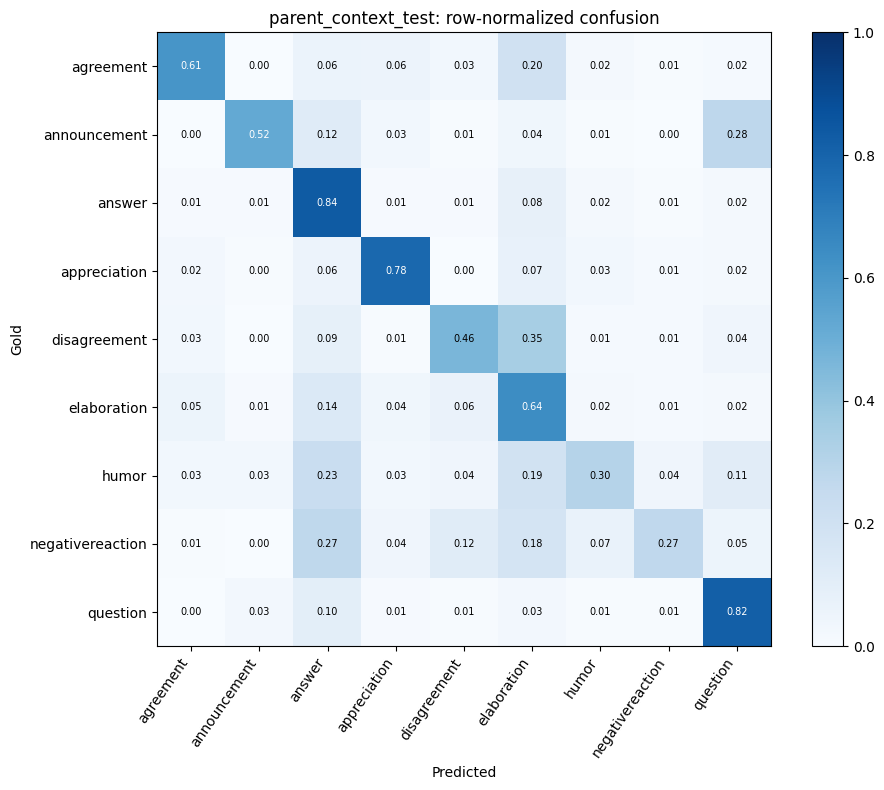

,id,conversation_id,text,parent_text,gold,prediction
0,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,"Ah, yes. That depends on the toddler of course...",I totally see where you are going with this an...,agreement,elaboration
1,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,and pulled over when your dad asked him to!,And apologized for creeping him out!,agreement,elaboration
2,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,"I too am in mass, some days are just bone chil...","Hello, I ride in Massachusetts winters and I f...",agreement,elaboration
3,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,"tis the best way to go i think, its a shame it...",Thanks for your input. That's why I wanted to ...,agreement,elaboration
4,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,He is an awesome guy. Funny and interesting bu...,Another Dan Savage fan!,agreement,appreciation
5,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,It does seem the chromebook has taken the netb...,"Cheap, light, good battery life, easy to set u...",agreement,elaboration
6,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,^^^^ ^ ^ ^,Of course no.,agreement,humor
7,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,"wasnt doing math when I did the comment, just ...",not exactly sure how you have 14 outs as 56% t...,agreement,elaboration
8,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,Exactly the same position! except my other hal...,"We're in the same boat then, I quit last night...",agreement,answer
9,reddit:reddit-coarse-discourse-corpus:utteranc...,reddit:reddit-coarse-discourse-corpus:conversa...,And even offered complementary blow job service!,What a nice guy. He gave your dad a ride and $50!,agreement,elaboration


,device,elapsed_seconds,peak_gpu_memory_bytes,best_dev_macro_f1,run
0,Tesla T4,1904.967980,1799810048,0.578525,parent_context
1,Tesla T4,1704.873832,1803553280,0.501196,plain
2,Tesla T4,562.480475,1803553280,0.435929,smoke
3,Tesla T4,1710.387234,1803553792,0.487755,weighted


In [22]:
import matplotlib.pyplot as plt
import numpy as np

INSPECT_EVALUATION = 'parent_context_test'
folder = RUN_ROOT / INSPECT_EVALUATION / 'transformer'
if (folder / 'metrics.json').is_file():
    metrics = json.loads((folder / 'metrics.json').read_text())
    display(pd.Series(metrics['per_class_f1'], name='F1').to_frame())
    confusion = json.loads((folder / 'normalized_confusion.json').read_text())
    matrix = np.array(confusion['matrix'])
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    ax.set(xticks=range(len(confusion['labels'])), yticks=range(len(confusion['labels'])),
           xticklabels=confusion['labels'], yticklabels=confusion['labels'],
           xlabel='Predicted', ylabel='Gold', title=f'{INSPECT_EVALUATION}: row-normalized confusion')
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right')
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center',
                    color='white' if matrix[i, j] > .5 else 'black', fontsize=7)
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(folder / 'normalized_confusion.png', dpi=160)
    plt.show()
    errors = json.loads((folder / 'misclassification_sample.json').read_text())
    display(pd.DataFrame(errors).head(30))
else:
    print('Run dev evaluation first, then select its directory above.')

compute = []
for path in sorted(RUN_ROOT.glob('*/compute.json')):
    row = json.loads(path.read_text())
    row.pop('versions', None)
    row['run'] = path.parent.name
    compute.append(row)
display(pd.DataFrame(compute))

## Final held-out test comparison (disabled by default)
After inspecting dev results, set `SELECTED_RUN` to the chosen full experiment and `RUN_FINAL_TEST = True` in the configuration cell. Evaluate that checkpoint and all baselines on the same test split. Do not choose models or adjust settings from test results. Add Task #3 only if its results use this exact split and filtering.

In [21]:
SELECTED_RUN = 'parent_context'  # Choose from full-run dev results, not the test set.
if RUN_FINAL_TEST:
    selected = RUN_ROOT / SELECTED_RUN
    if not (selected / 'compute.json').is_file():
        raise FileNotFoundError(f'Complete the selected training run first: {selected}')
    test_output = evaluate(f'{SELECTED_RUN}_test', run=selected, split='test', baselines=True)
    display(pd.read_csv(test_output / 'results.csv').round(4))
else:
    print('Test evaluation disabled; finish model selection on dev first.')

Running: /usr/bin/python3 -u /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/scripts/evaluate_discourse_models.py --data /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl --output /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/parent_context_test --split test --split-seed 42 --batch-size 16 --run /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/parent_context --baselines

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6095.61it/s]
{'model': 'majority', 'accuracy': 0.4161268490766702, 'macro_f1': 0.06529968214954901, 'weighted_f1': 0.2445565588073993}
{'model': 'tfidf_logreg', 'accuracy': 0.5550613941796384, 'macro_f1': 0.3223779750552599, 'weighted_f1': 0.5079407170614728}
{'model': 'tfidf_balanced_logreg', 'accuracy': 0.

,model,accuracy,macro_f1,weighted_f1
0,majority,0.4161,0.0653,0.2446
1,tfidf_logreg,0.5551,0.3224,0.5079
2,tfidf_balanced_logreg,0.4575,0.3850,0.4802
3,transformer,0.7376,0.5766,0.7387


In [23]:
plain_test_output = evaluate(
    'plain_test',
    run=RUN_ROOT / 'plain',
    split='test',
)

display(pd.read_csv(plain_test_output / 'results.csv').round(4))

Running: /usr/bin/python3 -u /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/scripts/evaluate_discourse_models.py --data /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/standardized-v1/reddit-coarse-discourse-corpus.jsonl --output /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/plain_test --split test --split-seed 42 --batch-size 16 --run /content/drive/MyDrive/Market-Research-1B-discussion-intelligence-toolkit/data/local/discourse_transformer/experiment_01/plain

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2777.56it/s]
{'model': 'transformer', 'accuracy': 0.6427535531277192, 'macro_f1': 0.49959283696968626, 'weighted_f1': 0.6289710199448357}


,model,accuracy,macro_f1,weighted_f1
0,transformer,0.6428,0.4996,0.629


## Record findings and preserve outputs
All run folders contain the exact split manifest. Training folders also contain configuration, per-epoch dev scores, the best checkpoint, compute measurements, and installed dependency versions; failures preserve a traceback and command log. Evaluation folders contain metrics, predictions, per-class F1, raw/normalized confusion, and sampled errors. If using temporary runtime storage instead of Drive, copy the run folder to persistent storage before disconnecting.

Complete the notes below from actual observations:

- **Experiment decisions:** Why did you select this loss/context setting? Which attempts failed or regressed?
- **Error patterns:** Which classes improved or still confuse the model? Give representative examples.
- **Compute:** GPU model, peak allocated memory, elapsed training time, inference throughput, and whether the measured run fit your free-tier session. Training timing covers the epoch loop and checkpoint writes, not dependency installation or model download.
- **Cost-benefit conclusion:** In one or two sentences, explain whether the macro-F1 gain over balanced TF-IDF justifies the measured training and inference cost.

The one-epoch smoke check does not establish full-run feasibility. This notebook has no precomputed transformer results.

# Task #4 report: compact transformer for discourse acts

**The selected DistilBERT model, using the parent comment and current comment, achieved 0.5766 macro F1 on the held-out test set, compared with 0.3850 for class-balanced TF-IDF logistic regression.** Accuracy was 0.7376 and weighted F1 was 0.7387. Selection used development results; the final comparison used the untouched test split.

## Data and evaluation protocol

The experiment used the complete standardized Coarse Discourse corpus. CGA-CMV was excluded because it has no discourse-act labels. To match the existing baseline notebook, preprocessing used `text_clean` and excluded synthetic placeholders, missing discourse labels, blank cleaned text, and the `other` label. Explicit `[deleted]` and `[removed]` markers were retained for baseline comparability. The resulting task has nine classes.

The existing `split_by_group` implementation assigned whole conversations to train, dev, or test using hash buckets with split seed 42 and nominal fractions of 80/10/10. The retained counts were **79,517 train, 9,373 dev, and 10,343 test comments**. Conversation isolation was checked, and each run saved a manifest containing example IDs, conversation IDs, split assignments, and fingerprints of text and labels. Model seed 42 was held fixed across the experiments.

Metrics were computed with the shared `artifacts/evaluation.py` harness. Macro F1 was the model-selection criterion because classes are imbalanced. The majority class was determined from training labels. Confusion matrices use gold classes on rows and predictions on columns; the normalized matrix divides each row by its gold-class support. The test matrix and sampled errors are displayed in the inspection cell above.

## Model and implementation

The model was `distilbert/distilbert-base-uncased`, fine-tuned with a nine-class classification head. The common settings were a learning rate of `2e-5`, batch size 16, maximum sequence length 256, gradient accumulation of 1, AdamW optimization, gradient clipping, and CUDA mixed precision. Full runs trained for three epochs and saved the checkpoint with the highest dev macro F1.

The weighted experiment used inverse-frequency class weights computed from training labels only. The selected context experiment used ordinary cross-entropy and tokenizer pairs containing the immediate parent's text followed by the current comment. Each component received half of the available token budget, excluding special tokens. Root comments and comments with synthetic parents used an empty parent string. No parent labels were supplied to the model.

Reusable code is in `artifacts/discourse_data.py` and `artifacts/discourse_transformer.py`, with command-line entry points in `scripts/train_discourse_transformer.py` and `scripts/evaluate_discourse_models.py`. This notebook invokes those scripts and displays their outputs. Transformer training is independent of cached embeddings and Task #3.

## Development experiments and modeling decisions

| Experiment | Epochs | Dev accuracy | Dev macro F1 | Dev weighted F1 | Decision |
|---|---:|---:|---:|---:|---|
| Majority, rerun | — | 0.4245 | 0.0662 | 0.2530 | Reference floor |
| TF-IDF + logistic regression, rerun | — | 0.5603 | 0.3180 | 0.5135 | Unweighted text baseline |
| Balanced TF-IDF + logistic regression, rerun | — | 0.4486 | 0.3735 | 0.4723 | Strongest baseline by macro F1 |
| DistilBERT, comment-only smoke run | 1 | 0.6533 | 0.4359 | 0.6260 | Verified real-model training and resource use |
| DistilBERT, comment-only | 3 | 0.6514 | 0.5012 | 0.6386 | Best comment-only configuration |
| DistilBERT, class-weighted comment-only | 3 | 0.5898 | 0.4878 | 0.6036 | Rejected: lower macro F1 than ordinary loss |
| **DistilBERT, parent context** | **3** | **0.7362** | **0.5785** | **0.7365** | **Selected before test evaluation** |

Comment-only dev macro F1 rose across epochs from 0.4357 to 0.4731 to 0.5012. Weighted training produced 0.4564, 0.4681, and 0.4878: it helped at the first epoch but did not beat ordinary training at the end of the common budget. Parent context produced 0.5338, 0.5766, and 0.5785; epoch 3 was selected. It added **0.0773 macro F1** over the best comment-only model.

The original published TF-IDF dev results were 0.5631 / 0.3213 / 0.5165 for ordinary logistic regression and 0.4487 / 0.3733 / 0.4723 for balanced logistic regression (accuracy / macro F1 / weighted F1). Rerun results differ slightly. The cause was not isolated, so the report preserves this discrepancy rather than claiming exact numerical reproduction. Final test comparisons use baselines rerun on the same split in the evaluation environment.

**Failures and setup issues:** the initial hardware check failed when no CUDA GPU was available. Training proceeded after switching to a T4 runtime. No completed modeling run shown in the saved outputs crashed. The HF Hub authentication warning did not prevent downloading the public checkpoint. Missing classification-head weights were expected initialization, not a failed experiment. The class-weighted run was an unsuccessful modeling alternative by the selection criterion, rather than an execution failure.

## Final held-out test results

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Majority class | 0.4161 | 0.0653 | 0.2446 |
| TF-IDF + logistic regression | 0.5551 | 0.3224 | 0.5079 |
| TF-IDF + class-balanced logistic regression | 0.4575 | 0.3850 | 0.4802 |
| DistilBERT, comment-only | 0.6428 | 0.4996 | 0.6290 |
| **DistilBERT + parent context** | **0.7376** | **0.5766** | **0.7387** |

The selected model improved test macro F1 by **0.1916**, or 19.16 percentage points, over balanced logistic regression. The comment-only transformer achieved **0.4996 macro F1**, an improvement of **0.1146** over balanced logistic regression; parent context added a further **0.0770**. Both transformer configurations generalized similarly to their dev results: comment-only macro F1 was 0.5012 on dev and 0.4996 on test, while parent-context macro F1 was 0.5785 on dev and 0.5766 on test. The comment-only checkpoint was evaluated on test afterward as an additional comparison, without retraining or changing the model selected from dev results. Task #3 results were not included because they were not available in these outputs.

## Per-class test F1 and error analysis

| Class | Test F1 |
|---|---:|
| Agreement | 0.6187 |
| Announcement | 0.4348 |
| Answer | 0.8378 |
| Appreciation | 0.7896 |
| Disagreement | 0.4522 |
| Elaboration | 0.6313 |
| Humor | 0.2957 |
| Negative reaction | 0.2987 |
| Question | 0.8303 |

Answers, questions, and appreciation were the strongest classes. Humor and negative reactions remained the weakest. The normalized test confusion matrix shows these main patterns (percentages are approximate because the displayed cells are rounded):

- **Disagreement versus elaboration:** 35% of disagreements were predicted as elaboration, compared with 46% correctly recognized. Parent context helps identify the reply's relationship to its parent, but criticism can still resemble an explanation or continuation.
- **Agreement with added detail:** 20% of agreements were classified as elaboration. In the error sample, “It does seem the chromebook has taken the netbook market over” was labeled agreement but predicted elaboration after a parent discussing the device's advantages. This illustrates overlapping discourse functions; it does not establish that the gold label is wrong.
- **Announcement versus question:** 28% of announcements were predicted as questions. Several sampled announcement errors were root posts with empty parent text, so additional parent context could not help them.
- **Answers with another surface function:** “Seconding Phinix natural ENB...” was labeled answer but predicted agreement. Replies can both answer a request and endorse an earlier suggestion.
- **Sparse or unavailable text:** a `[deleted]` example labeled answer was predicted question. Such markers contain little recoverable evidence and remain a limitation of the baseline-compatible dataset.

On dev, parent context reduced elaboration-to-answer confusion from about 53% to 15%, and disagreement-to-answer confusion from 38% to 8%. These class-level confusion comparisons use the two dev models; a corresponding comparison of their test confusion matrices was not performed for this report. On test, the selected model misclassified about 14% of elaborations and 9% of disagreements as answers. Negative-reaction dev F1 declined from 0.3370 to 0.3117 with context, so the benefit was not uniform across classes.

The evaluation script saved all predictions and a reproducible sample of up to ten errors per gold class. The notebook display shows only the first 30 sampled rows, covering agreement, announcement, and answer; broader claims about the other classes above rely on the confusion matrix and per-class scores, not a complete manual review of their examples.

## Compute, runtime, and reproducibility

All measured training runs used a Tesla T4 with 14.56 GiB device memory available to the runtime.

| Run | Training-loop time | Peak allocated GPU memory |
|---|---:|---:|
| One-epoch smoke | 9.4 minutes | 1.68 GiB |
| Comment-only, three epochs | 28.4 minutes | 1.68 GiB |
| Class-weighted, three epochs | 28.5 minutes | 1.68 GiB |
| Parent context, three epochs | 31.7 minutes | 1.68 GiB |

The recorded training loops totaled about **98.0 minutes**, excluding separate evaluation runs. Timing includes epoch training, in-loop dev evaluation, and checkpoint writing, but excludes dependency installation and initial model loading/download. Peak memory is PyTorch's peak allocated memory, not total device usage. The selected model therefore fit the T4 session used for this free-tier-targeted experiment, with substantial memory headroom. The displayed measurements do not establish inference throughput or total end-to-end session cost; per-model evaluation folders contain separate inference timing JSON files for that analysis.

The smoke run recorded PyTorch `2.11.0+cu130`, Transformers `5.21.0`, and scikit-learn `1.6.1`. Each completed training run saved its own exact dependency versions in `compute.json`. Runs used a single model seed, so variance across training seeds and confidence intervals were not measured. The parent-context comparison also changes the child truncation budget and tokenization path; it is a practical input-configuration comparison, not an isolated measurement of parent information alone.

Outputs are stored under `data/local/discourse_transformer/experiment_01/` in the Drive project folder. Training directories contain configuration, dev history, compute measurements, split manifests, and the best checkpoint. `parent_context_test/` contains the final `results.csv` and per-model metrics, predictions, raw and normalized confusion matrices, error samples, and inference timing. `plain_test/` contains the additional comment-only test evaluation, including its `results.csv` and transformer metrics, predictions, confusion matrices, error samples, and inference timing. The transformer inspection additionally saved `normalized_confusion.png` for the selected parent-context test model. Keep large model checkpoints and corpus files out of Git.

## Does the improvement justify the cost?

For this task, the **0.1916 test macro-F1 improvement over balanced TF-IDF justifies the measured 31.7-minute T4 training run**, with the comment-only transformer contributing 0.1146 and parent context adding another 0.0770 for about 3.3 additional training minutes. Parent context remains the configuration selected from dev results; deployment should still measure inference throughput and account for the remaining weakness on humor, negative reactions, and disagreement.
